# Portfolio Market Risk Case Study

## Multi-Risk-Factor VaR, Expected Shortfall, Stress Testing and Basel-Oriented ES

**Risk Engine:** `RiskEngine`  
**Confidence Levels:** 95%, 97.5% and 99%  
**Holding Periods:** 1-day, 10-day, 21-day and 252-day  
**Risk Factors:** EURUSD, GBPUSD, USDJPY, S&P 500, Gold  
**Risk Measures:** Value at Risk (VaR), Expected Shortfall (ES) and Stress Loss  
**Methodologies:** Historical, Parametric and Monte Carlo  
**Basel-Oriented ES:** 97.5% one-tailed ES with a 10-day base horizon  

> **Scope:** The project combines general portfolio market-risk analysis with a Basel-oriented Expected Shortfall extension. The Basel-oriented component is an educational implementation of selected Basel IMA concepts and is not intended to represent a complete regulatory capital calculation.

## Executive Summary

This case study develops and evaluates a simplified multi-asset market-risk framework using five risk factors: EURUSD, GBPUSD, USDJPY, the S&P 500, and Gold.

The project first establishes a core risk engine capable of calculating Value at Risk (VaR) and Expected Shortfall (ES) using Historical, Parametric, and Monte Carlo methodologies across multiple confidence levels and holding periods. The engine is then applied to a portfolio-level case study and evaluated through comparative risk analysis, risk-factor diagnostics, and stress testing.

The analysis includes 95% and 99% VaR and ES for general risk assessment, together with predefined stress scenarios and a historical worst-loss scenario. A Basel-oriented extension is also incorporated using a 97.5% one-tailed ES framework with a 10-day base horizon.

The project demonstrates how different risk methodologies, confidence levels, holding periods, and stress scenarios can produce different views of portfolio market risk. It also provides a foundation for extending the risk engine toward more advanced Basel/FRTB concepts in subsequent projects.

The portfolio uses fictional sensitivities within a simplified linear framework. The project is intended as a practical market-risk modelling and learning case study and is not a complete regulatory capital implementation.

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import norm
import yfinance as yf

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

import matplotlib.cm as cm

In [2]:
from risk_engine import RiskEngine

print("RiskEngine imported successfully.")

RiskEngine imported successfully.


## Portfolio Setup

The portfolio is represented using simplified linear sensitivities to five market risk factors:

- EURUSD
- GBPUSD
- USDJPY
- S&P 500
- Gold

Each sensitivity represents the approximate portfolio P&L impact associated with a 100% move in the corresponding risk factor.

The sensitivities are fictional portfolio-level inputs created for this case study. They are not trade-level positions and do not represent actual market holdings.

The linear sensitivity framework provides a consistent portfolio representation for Historical, Parametric, and Monte Carlo risk calculations.

In [3]:
sensitivities = pd.Series({
    "EURUSD": 5_000_000,
    "GBPUSD": 3_000_000,
    "USDJPY": 4_000_000,
    "SP500": 2_000_000,
    "GOLD": 1_000_000
})

sensitivities

,0
EURUSD,5000000
GBPUSD,3000000
USDJPY,4000000
SP500,2000000
GOLD,1000000


## Market Data

Daily market data is collected for the five portfolio risk factors: EURUSD, GBPUSD, USDJPY, the S&P 500, and Gold.

A five-year daily history is used as the market-data sample for the general Historical, Parametric, and Monte Carlo risk calculations.

This dataset supports the portfolio risk analysis in this case study. The Basel-oriented stressed-ES extension is treated separately because a full Basel implementation requires a substantially longer historical observation period.

In [4]:
tickers = {
    "EURUSD": "EURUSD=X",
    "GBPUSD": "GBPUSD=X",
    "USDJPY": "JPY=X",
    "SP500": "^GSPC",
    "GOLD": "GC=F"
}

raw_data = yf.download(
    list(tickers.values()),
    period="5y",
    auto_adjust=False,
    progress=False
)

print("Market data downloaded successfully.")
print(f"Observations: {len(raw_data)}")

Market data downloaded successfully.
Observations: 1301


## Market Price Preparation

The downloaded closing-price data is aligned to the five portfolio risk factors and restricted to the factors used in the analysis.

Rows with missing observations are removed to create a synchronized time series for the risk calculations.

In [5]:
market_prices = raw_data["Close"].copy()

market_prices = market_prices.rename(columns={
    "EURUSD=X": "EURUSD",
    "GBPUSD=X": "GBPUSD",
    "JPY=X": "USDJPY",
    "^GSPC": "SP500",
    "GC=F": "GOLD"
})

market_prices = market_prices[
    ["EURUSD", "GBPUSD", "USDJPY", "SP500", "GOLD"]
]

market_prices = market_prices.dropna()

print("Market price data prepared successfully.")
print(f"Observations after cleaning: {len(market_prices)}")

market_prices.tail()

Market price data prepared successfully.
Observations after cleaning: 1253


Ticker,EURUSD,GBPUSD,USDJPY,SP500,GOLD
Date,,,,,
2026-10-15,1.119507,1.323014,157.957001,7744.060059,4170.100098
2026-10-16,1.121315,1.327316,158.143005,7659.439941,4181.100098
2026-10-19,1.122549,1.333565,157.806000,7690.729980,4160.100098
2026-10-20,1.121579,1.330849,158.522995,7712.569824,4142.600098
2026-10-21,1.123595,1.339567,158.132996,7757.169922,4157.799805


## Return Calculation

Daily percentage returns are calculated from the synchronized closing-price series.

These returns represent the observed market movements used by the risk engine to estimate portfolio P&L under the Historical, Parametric, and Monte Carlo methodologies.

In [6]:
returns = market_prices.pct_change(fill_method=None).dropna()

print("Daily returns calculated successfully.")
print(f"Observations: {len(returns)}")
print(f"Risk factors: {list(returns.columns)}")

returns.head()

Daily returns calculated successfully.
Observations: 1252
Risk factors: ['EURUSD', 'GBPUSD', 'USDJPY', 'SP500', 'GOLD']


Ticker,EURUSD,GBPUSD,USDJPY,SP500,GOLD
Date,,,,,
2021-10-25,0.001269,-0.002064,-0.001634,0.004748,0.005845
2021-10-26,-0.002438,0.000124,0.000889,0.001820,-0.007416
2021-10-27,-0.001160,0.000124,0.003718,-0.005052,0.003011
2021-10-28,0.000162,-0.002417,-0.003608,0.009829,0.002112
2021-10-29,0.007197,0.004941,-0.001406,0.001949,-0.010374


## Risk Engine Initialization

The cleaned market-price history and portfolio sensitivities are passed to the `RiskEngine`.

The engine uses the risk-factor price history and portfolio sensitivities to calculate portfolio P&L and estimate VaR and Expected Shortfall across different methodologies, confidence levels, and holding periods.

In [7]:
engine = RiskEngine(
    sensitivities=sensitivities,
    risk_factor_prices=market_prices
)

print("Portfolio RiskEngine initialized successfully.")

Portfolio RiskEngine initialized successfully.


## Risk Calculation Grid

Portfolio risk is evaluated across three methodologies, two confidence levels, and four holding periods.

The resulting 24 scenarios provide a consistent comparison of how estimated VaR and Expected Shortfall change with methodology, confidence level, and holding period.

A separate Basel-oriented Expected Shortfall analysis is added later using a 97.5% one-tailed confidence level and a 10-day base horizon.

In [8]:
# Calculate portfolio risk across confidence levels,
# methodologies, and holding periods

results = []

confidence_levels = [0.95, 0.99]
methodologies = ["historical", "parametric", "monte_carlo"]
horizons = [1, 10, 21, 252]

for confidence in confidence_levels:
    for methodology in methodologies:
        for horizon in horizons:

            result = engine.calculate(
                confidence=confidence,
                horizon=horizon,
                methodology=methodology
            )

            results.append({
                "Confidence": confidence,
                "Methodology": methodology.replace("_", " ").title(),
                "Horizon (Days)": horizon,
                "VaR": result["VaR"],
                "Expected Shortfall": result["Expected Shortfall"]
            })

print(f"Total scenarios calculated: {len(results)}")

Total scenarios calculated: 24


In [9]:
risk_results = pd.DataFrame(results)

print(f"Total scenarios calculated: {len(risk_results)}")

Total scenarios calculated: 24


In [10]:
# Format risk results for presentation

def make_comparison_table(confidence, metric, label_suffix):
    table = (
        risk_results[risk_results["Confidence"] == confidence]
        .pivot(
            index="Horizon (Days)",
            columns="Methodology",
            values=metric
        )
        .reindex(columns=["Historical", "Parametric", "Monte Carlo"])
        .reset_index()
    )

    table.columns.name = None

    table = table.rename(columns={
        "Horizon (Days)": "Horizon",
        "Historical": f"Historical {label_suffix}",
        "Parametric": f"Parametric {label_suffix}",
        "Monte Carlo": f"Monte Carlo {label_suffix}"
    })

    return table[
        [
            "Horizon",
            f"Historical {label_suffix}",
            f"Parametric {label_suffix}",
            f"Monte Carlo {label_suffix}"
        ]
    ].style.hide(axis="index").format({
        f"Historical {label_suffix}": "{:,.2f}",
        f"Parametric {label_suffix}": "{:,.2f}",
        f"Monte Carlo {label_suffix}": "{:,.2f}"
    })


var_95 = make_comparison_table(0.95, "VaR", "VaR")
var_99 = make_comparison_table(0.99, "VaR", "VaR")

es_95 = make_comparison_table(0.95, "Expected Shortfall", "ES")
es_99 = make_comparison_table(0.99, "Expected Shortfall", "ES")


print("95% Confidence Level — VaR Comparison")
display(var_95)

print("99% Confidence Level — VaR Comparison")
display(var_99)

print("95% Confidence Level — Expected Shortfall Comparison")
display(es_95)

print("99% Confidence Level — Expected Shortfall Comparison")
display(es_99)

95% Confidence Level — VaR Comparison


Horizon,Historical VaR,Parametric VaR,Monte Carlo VaR
1,"70,732.71","70,169.30","67,852.81"
10,"223,238.42","221,894.81","214,569.44"
21,"303,811.47","321,556.13","310,940.66"
252,"189,755.71","1,113,903.10","1,077,130.04"


99% Confidence Level — VaR Comparison


Horizon,Historical VaR,Parametric VaR,Monte Carlo VaR
1,"103,021.71","99,241.78","95,905.63"
10,"338,660.02","313,830.06","303,280.23"
21,"476,343.51","454,782.97","439,494.81"
252,"424,749.73","1,575,414.41","1,522,454.68"


95% Confidence Level — Expected Shortfall Comparison


Horizon,Historical ES,Parametric ES,Monte Carlo ES
1,"96,438.06","87,995.13","85,585.64"
10,"304,675.13","278,265.04","270,645.57"
21,"399,530.89","403,244.36","392,202.69"
252,"338,707.78","1,396,879.43","1,358,629.97"


99% Confidence Level — Expected Shortfall Comparison


Horizon,Historical ES,Parametric ES,Monte Carlo ES
1,"141,906.07","113,697.79","112,552.34"
10,"434,407.19","359,543.97","355,921.74"
21,"529,584.53","521,028.71","515,779.61"
252,"482,301.77","1,804,896.40","1,786,712.97"


## Risk Results Comparison

The 24 portfolio risk scenarios are presented across four comparison tables covering 95% and 99% VaR and Expected Shortfall.

Each table compares Historical, Parametric, and Monte Carlo estimates across 1-day, 10-day, 21-day, and 252-day holding periods.

The results show how portfolio risk changes with confidence level, holding period, and modelling methodology.

At shorter horizons, the three methodologies produce broadly comparable estimates. At the 252-day horizon, Parametric and Monte Carlo estimates are substantially higher than the corresponding Historical estimates because the model applies square-root-of-time scaling to the one-day risk distribution, while Historical risk is derived directly from observed multi-day returns.

Expected Shortfall is higher than VaR at the same confidence level and holding period, reflecting the average severity of losses beyond the VaR threshold.

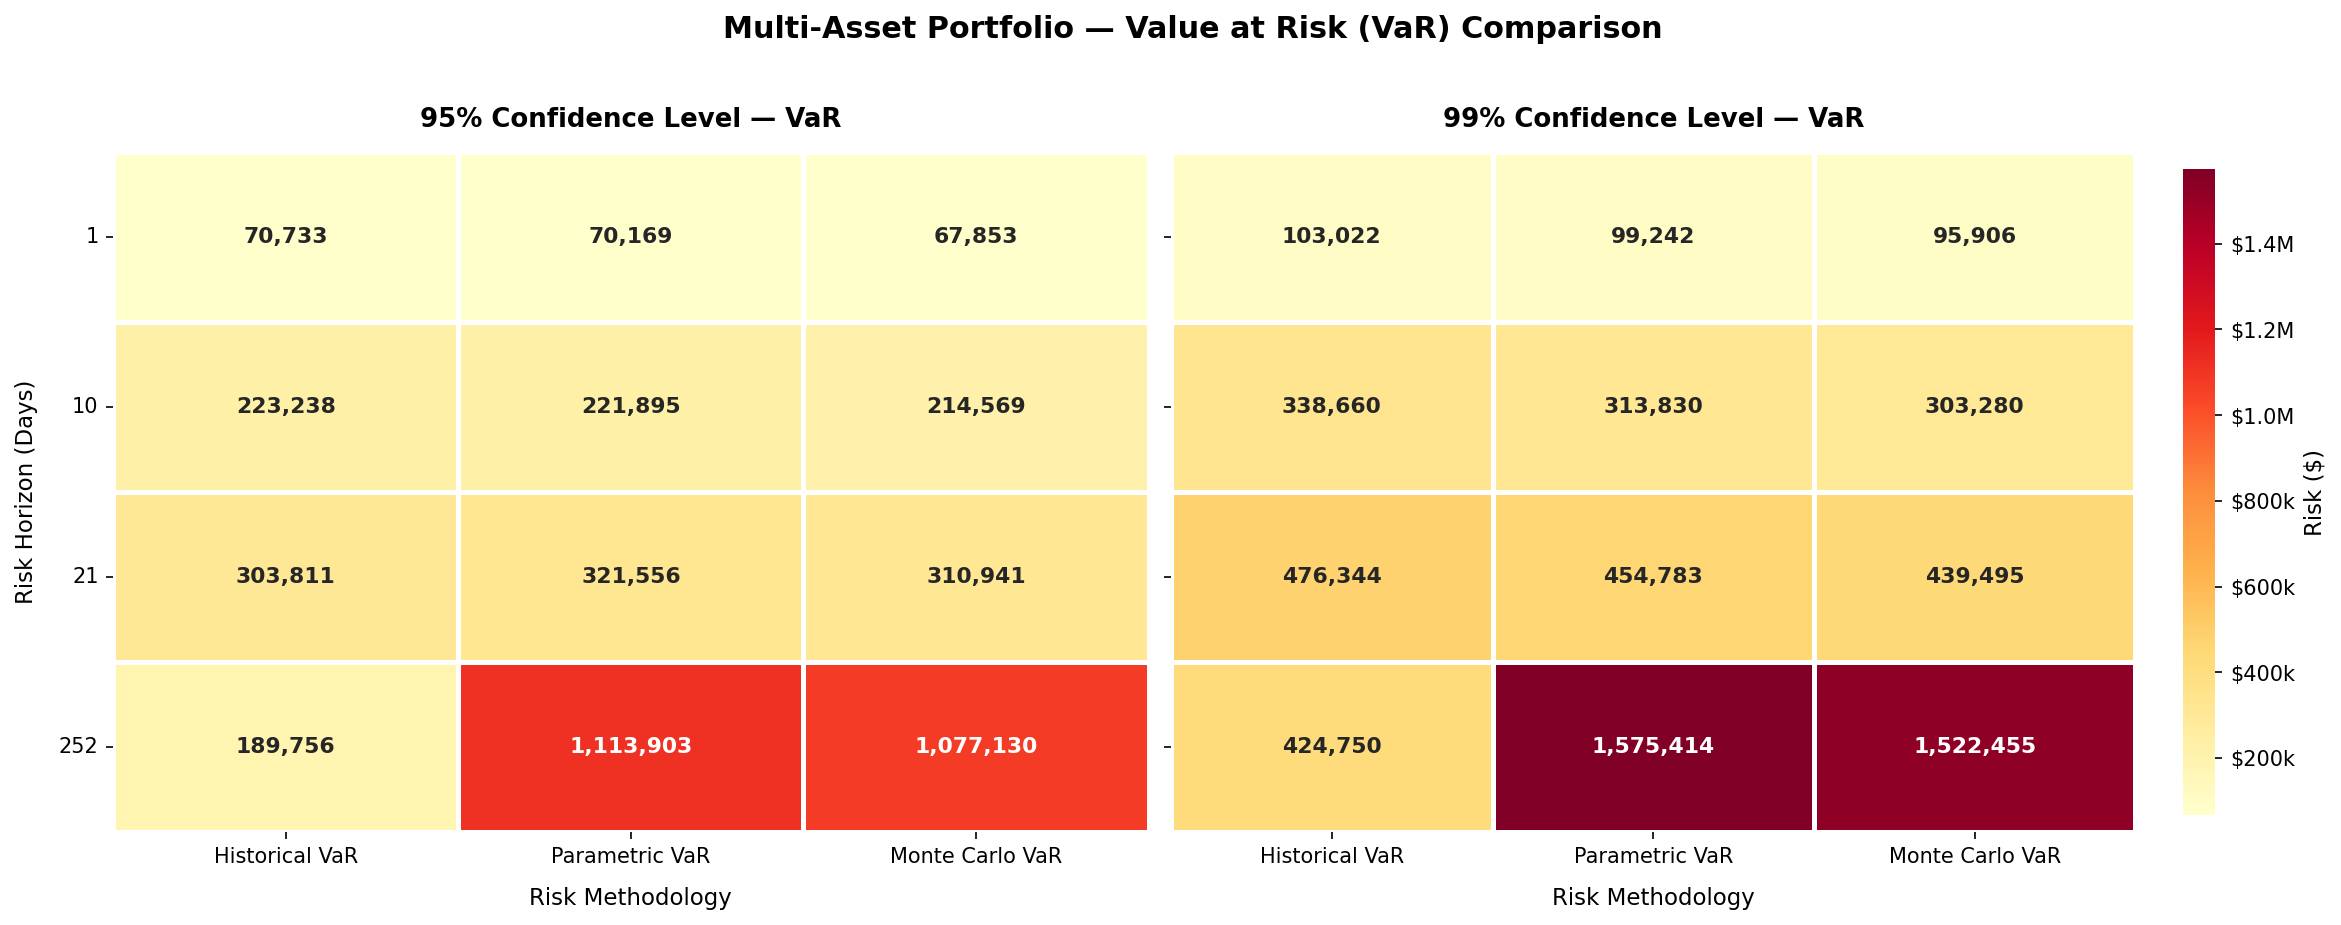

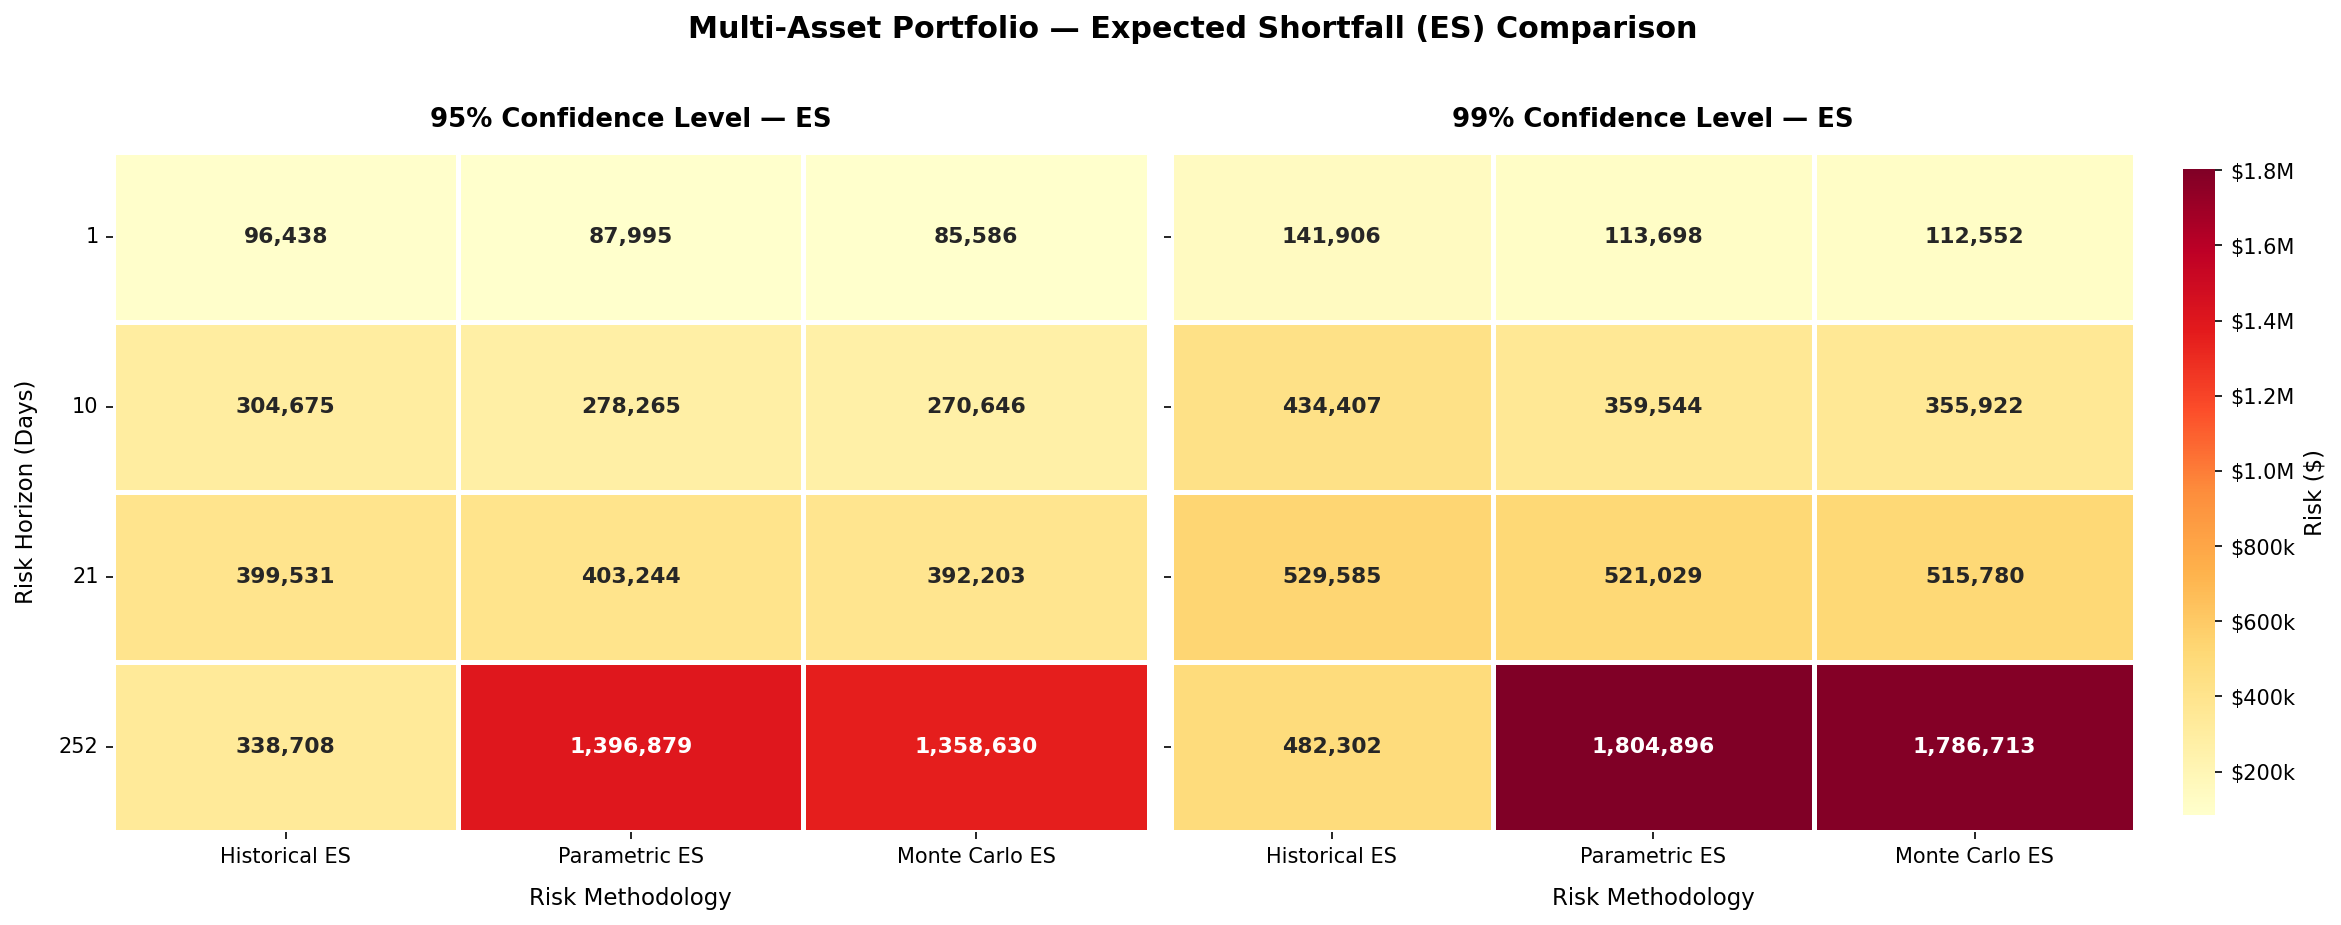

In [11]:
# ============================================================
# VaR and Expected Shortfall Heatmaps
# ============================================================

# 1. Function to dynamically extract raw numeric matrices from risk_results
def get_raw_table(confidence, metric, label_suffix):
    table = (
        risk_results[risk_results["Confidence"] == confidence]
        .pivot(
            index="Horizon (Days)",
            columns="Methodology",
            values=metric
        )
        .reindex(columns=["Historical", "Parametric", "Monte Carlo"])
    )

    table.index.name = "Horizon"
    table.columns.name = None

    table = table.rename(columns={
        "Historical": f"Historical {label_suffix}",
        "Parametric": f"Parametric {label_suffix}",
        "Monte Carlo": f"Monte Carlo {label_suffix}"
    })

    return table


# 2. Extract DataFrames dynamically
#    These update automatically if risk_results changes
var_95_df = get_raw_table(0.95, "VaR", "VaR")
var_99_df = get_raw_table(0.99, "VaR", "VaR")

es_95_df = get_raw_table(0.95, "Expected Shortfall", "ES")
es_99_df = get_raw_table(0.99, "Expected Shortfall", "ES")


# 3. Currency formatter for colorbar ($k / $M)
def currency_fmt(x, pos):
    if x >= 1e6:
        return f"${x*1e-6:.1f}M"
    return f"${x*1e-3:.0f}k"


formatter = FuncFormatter(currency_fmt)


# 4. Heatmap setup
pairs = [
    {
        "measure": "Value at Risk (VaR)",
        "t1_title": "95% Confidence Level — VaR",
        "t1_data": var_95_df,
        "t2_title": "99% Confidence Level — VaR",
        "t2_data": var_99_df
    },
    {
        "measure": "Expected Shortfall (ES)",
        "t1_title": "95% Confidence Level — ES",
        "t1_data": es_95_df,
        "t2_title": "99% Confidence Level — ES",
        "t2_data": es_99_df
    }
]


# 5. Render the heatmaps
for pair in pairs:

    t1 = pair["t1_data"]
    t2 = pair["t2_data"]

    # Dynamic shared color limits
    vmin = min(t1.values.min(), t2.values.min())
    vmax = max(t1.values.max(), t2.values.max())

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 6),
        dpi=150,
        sharey=True,
        gridspec_kw={"width_ratios": [1, 1.15]}
    )


    # --------------------------------------------------------
    # 95% Confidence Panel
    # --------------------------------------------------------
    sns.heatmap(
        t1,
        annot=True,
        fmt=",.0f",
        cmap="YlOrRd",
        vmin=vmin,
        vmax=vmax,
        linewidths=1.5,
        linecolor="white",
        cbar=False,
        annot_kws={
            "fontsize": 10.5,
            "fontweight": "semibold"
        },
        ax=axes[0]
    )

    axes[0].set_title(
        pair["t1_title"],
        fontsize=12.5,
        fontweight="bold",
        pad=12
    )

    axes[0].set_xlabel(
        "Risk Methodology",
        fontsize=11,
        labelpad=10
    )

    axes[0].set_ylabel(
        "Risk Horizon (Days)",
        fontsize=11,
        labelpad=10
    )

    axes[0].tick_params(axis="x", rotation=0)
    axes[0].tick_params(axis="y", rotation=0)


    # --------------------------------------------------------
    # 99% Confidence Panel
    # --------------------------------------------------------
    heatmap_right = sns.heatmap(
        t2,
        annot=True,
        fmt=",.0f",
        cmap="YlOrRd",
        vmin=vmin,
        vmax=vmax,
        linewidths=1.5,
        linecolor="white",
        cbar=True,
        cbar_kws={
            "label": "Risk ($)",
            "pad": 0.04,
            "shrink": 0.95
        },
        annot_kws={
            "fontsize": 10.5,
            "fontweight": "semibold"
        },
        ax=axes[1]
    )

    axes[1].set_title(
        pair["t2_title"],
        fontsize=12.5,
        fontweight="bold",
        pad=12
    )

    axes[1].set_xlabel(
        "Risk Methodology",
        fontsize=11,
        labelpad=10
    )

    axes[1].set_ylabel("")

    axes[1].tick_params(axis="x", rotation=0)
    axes[1].tick_params(axis="y", rotation=0)


    # --------------------------------------------------------
    # Format colorbar labels
    # --------------------------------------------------------
    cbar = heatmap_right.collections[0].colorbar
    cbar.formatter = formatter
    cbar.update_ticks()
    cbar.ax.yaxis.label.set_size(11)


    # --------------------------------------------------------
    # Overall figure title
    # --------------------------------------------------------
    fig.suptitle(
        f"Multi-Asset Portfolio — {pair['measure']} Comparison",
        fontsize=14.5,
        fontweight="bold",
        y=1.02
    )

    plt.tight_layout()
    plt.show()

## Risk-Factor P&L Volatility

The portfolio sensitivity to each risk factor is combined with its historical return volatility to estimate the standalone variability of its P&L impact.

This provides a diagnostic view of which risk factors exhibit the largest P&L volatility under the linear sensitivity framework.

This measure is not a formal portfolio risk contribution, Component VaR, or Marginal VaR because it does not allocate total portfolio VaR across risk factors.

In [12]:
# Calculate standalone risk-factor P&L volatility

risk_factor_volatility = (
    returns.std()
    * sensitivities.abs()
)

risk_factor_volatility = (
    risk_factor_volatility
    .sort_values(ascending=False)
    .rename("P&L Volatility")
)

risk_factor_volatility_df = risk_factor_volatility.reset_index()

risk_factor_volatility_df.columns = [
    "Risk Factor",
    "P&L Volatility"
]

display(
    risk_factor_volatility_df.style
    .hide(axis="index")
    .format({
        "P&L Volatility": "${:,.2f}"
    })
)

Risk Factor,P&L Volatility
USDJPY,"$25,216.09"
EURUSD,"$24,104.52"
SP500,"$21,317.20"
GBPUSD,"$16,116.14"
GOLD,"$12,041.04"


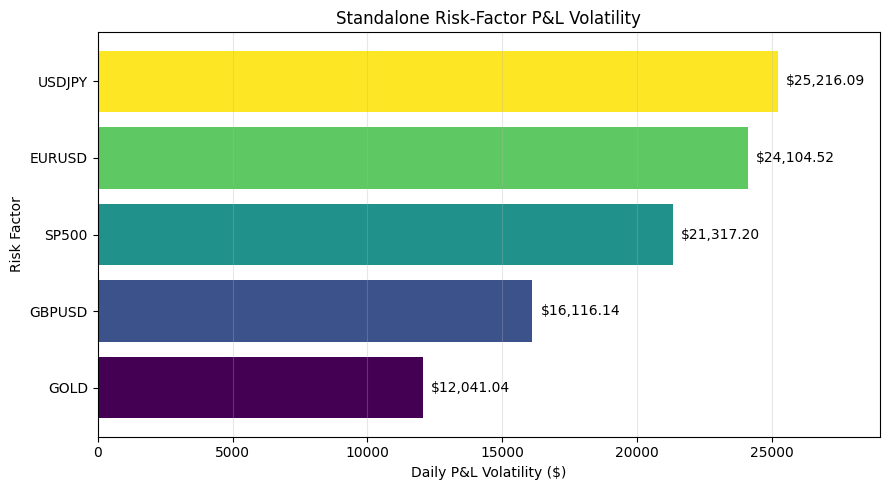

In [13]:
plt.figure(figsize=(9, 5))

data = risk_factor_volatility.sort_values()

colors = cm.viridis(
    [i / (len(data) - 1) for i in range(len(data))]
)

bars = plt.barh(
    data.index,
    data.values,
    color=colors
)

# Add values to the end of each bar
for bar, value in zip(bars, data.values):
    plt.text(
        bar.get_width() + 300,
        bar.get_y() + bar.get_height() / 2,
        f"${value:,.2f}",
        va="center"
    )

plt.title("Standalone Risk-Factor P&L Volatility")
plt.xlabel("Daily P&L Volatility ($)")
plt.ylabel("Risk Factor")
plt.xlim(0, data.max() * 1.15)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Stress Testing

Stress testing evaluates the portfolio under predefined adverse market scenarios rather than estimating losses from a probability distribution, as in VaR and Expected Shortfall.

The analysis applies common return shocks ranging from -1% to -5% across all five risk factors under the simplified linear sensitivity framework.

The analysis also identifies the historical worst portfolio-loss day in the available sample. The resulting portfolio loss is converted into an equivalent common shock based on the portfolio's total sensitivity. This is a portfolio-equivalent shock and should not be interpreted as the actual return of every risk factor on that date.

The stress scenarios are hypothetical and are intended to demonstrate scenario-based portfolio risk analysis. They are not calibrated to a specific regulatory stress-testing framework.

Historical Worst Day
Date: 2022-06-13
Portfolio-equivalent shock: -1.35%
Portfolio loss: $202,259.67


Scenario,Return Shock,Portfolio Stress Loss
-1% Common Shock,-1.00%,"$150,000.00"
Historical Worst Day,-1.35%,"$202,259.67"
-2% Common Shock,-2.00%,"$300,000.00"
-3% Common Shock,-3.00%,"$450,000.00"
-5% Common Shock,-5.00%,"$750,000.00"


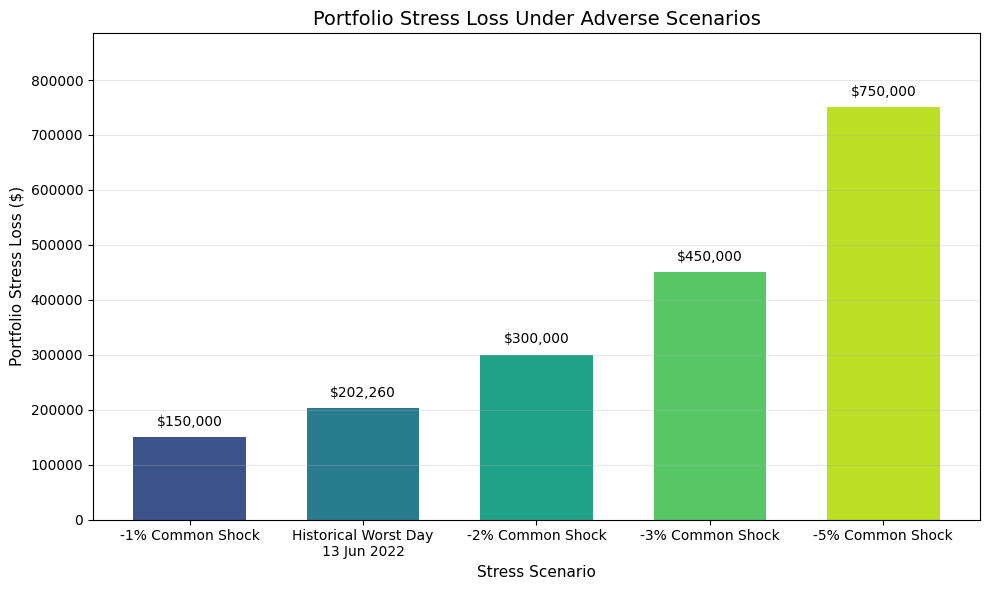

In [14]:
# ============================================================
# Stress Testing
# ============================================================

# ------------------------------------------------------------
# 1. Identify the historical worst portfolio-loss day
# ------------------------------------------------------------

historical_pnl = returns @ sensitivities

worst_day = historical_pnl.idxmin()
worst_day_pnl = historical_pnl.loc[worst_day]

# Total portfolio sensitivity
portfolio_sensitivity = sensitivities.sum()

# Convert the historical portfolio loss into a
# portfolio-equivalent common return shock
historical_worst_return = (
    worst_day_pnl / portfolio_sensitivity
)


# ------------------------------------------------------------
# 2. Define stress scenarios
# ------------------------------------------------------------

stress_scenarios = [
    ("-1% Common Shock", -0.01),
    ("Historical Worst Day", historical_worst_return),
    ("-2% Common Shock", -0.02),
    ("-3% Common Shock", -0.03),
    ("-5% Common Shock", -0.05)
]


# ------------------------------------------------------------
# 3. Calculate portfolio stress loss
# ------------------------------------------------------------

stress_results = []

for scenario, shock in stress_scenarios:

    loss = engine.stress_loss(shock)

    stress_results.append({
        "Scenario": scenario,
        "Return Shock": shock,
        "Portfolio Stress Loss": loss
    })


stress_analysis = pd.DataFrame(stress_results)


# ------------------------------------------------------------
# 4. Display historical worst-day information
# ------------------------------------------------------------

print("Historical Worst Day")
print(f"Date: {worst_day.date()}")
print(
    f"Portfolio-equivalent shock: "
    f"{historical_worst_return:.2%}"
)
print(
    f"Portfolio loss: "
    f"${abs(worst_day_pnl):,.2f}"
)


# ------------------------------------------------------------
# 5. Display stress scenario table
# ------------------------------------------------------------

display(
    stress_analysis.style
    .hide(axis="index")
    .format({
        "Return Shock": "{:.2%}",
        "Portfolio Stress Loss": "${:,.2f}"
    })
)


# ------------------------------------------------------------
# 6. Prepare dynamic chart labels
# ------------------------------------------------------------

plot_data = stress_analysis.copy()

historical_date_label = worst_day.strftime("%d %b %Y")

plot_labels = [
    scenario if scenario != "Historical Worst Day"
    else f"Historical Worst Day\n{historical_date_label}"
    for scenario in plot_data["Scenario"]
]


# ------------------------------------------------------------
# 7. Plot stress losses
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

colors = plt.cm.viridis(
    np.linspace(0.25, 0.9, len(plot_data))
)

bars = plt.bar(
    plot_labels,
    plot_data["Portfolio Stress Loss"],
    color=colors,
    width=0.65
)


# Add loss values above each bar
for bar, value in zip(
    bars,
    plot_data["Portfolio Stress Loss"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15000,
        f"${value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10
    )


plt.title(
    "Portfolio Stress Loss Under Adverse Scenarios",
    fontsize=14
)

plt.xlabel(
    "Stress Scenario",
    fontsize=11
)

plt.ylabel(
    "Portfolio Stress Loss ($)",
    fontsize=11
)

plt.ylim(
    0,
    plot_data["Portfolio Stress Loss"].max() * 1.18
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

## Risk Interpretation

The portfolio risk analysis compares Historical, Parametric, and Monte Carlo methodologies across 95% and 99% confidence levels and multiple holding periods.

### Confidence Level

Increasing the confidence level from 95% to 99% results in higher VaR and Expected Shortfall estimates across all three methodologies. This reflects greater focus on the extreme tail of the portfolio loss distribution.

### Methodology Comparison

At shorter holding periods, the Historical, Parametric, and Monte Carlo approaches produce broadly comparable risk estimates.

Parametric and Monte Carlo estimates are closely aligned because both use the portfolio's historical covariance structure and normal-distribution assumptions. Monte Carlo estimates the loss distribution through simulation, while the Parametric approach derives the risk estimate analytically.

The Historical approach uses observed historical market movements without imposing a normal-distribution assumption. Differences between Historical and normal-based methodologies therefore reflect the influence of historical observations and distributional assumptions.

### Holding Period

Parametric and Monte Carlo estimates increase substantially at longer horizons because the model applies square-root-of-time scaling to the one-day risk distribution.

Historical VaR does not necessarily increase monotonically with the holding period because multi-day historical returns are constructed directly from observed market prices. The resulting finite-sample distributions can therefore produce non-monotonic estimates across horizons.

### Expected Shortfall

Expected Shortfall is higher than VaR at the same confidence level and holding period because VaR identifies a tail-loss threshold, whereas Expected Shortfall measures the average loss beyond that threshold.

Expected Shortfall therefore provides additional information about the severity of losses once the VaR threshold has been exceeded.

### Risk-Factor Volatility

The standalone risk-factor P&L volatility analysis indicates that USDJPY and EURUSD exhibit the highest individual P&L volatility under the simplified sensitivity framework, followed by the S&P 500, GBPUSD, and Gold.

This is a diagnostic measure of individual factor sensitivity and volatility. It should not be interpreted as Component VaR, Marginal VaR, or a formal portfolio risk contribution.

### Stress Testing

The stress analysis complements the statistical risk measures by evaluating predefined adverse scenarios.

Under the linear sensitivity framework, portfolio stress losses increase proportionally with the magnitude of the common return shock.

The historical worst-loss scenario provides an additional reference point based on the portfolio's observed historical P&L. Its associated common shock is a portfolio-equivalent measure and should not be interpreted as the actual return of every risk factor on that date.

### Overall Assessment

No single risk methodology provides a complete view of portfolio risk.

Historical VaR captures observed market behavior, Parametric VaR provides an analytical estimate under distributional assumptions, Monte Carlo simulation provides a simulated loss distribution, Expected Shortfall provides additional information about tail-loss severity, and stress testing evaluates the portfolio under predefined adverse scenarios.

Together, these measures provide a broader assessment of portfolio market risk within the simplified linear sensitivity framework used in this case study.

## Limitations

The analysis is designed as an illustrative portfolio market-risk case study and has several important limitations.

### 1. Linear Sensitivity Framework

The portfolio is represented using fixed linear sensitivities to the selected risk factors. The framework therefore does not perform full instrument-level revaluation.

Nonlinear instruments such as options may exhibit material gamma, vega, and other nonlinear risk effects that are not captured by this approach.

### 2. Limited Risk Factors

The portfolio contains five simplified risk factors: EURUSD, GBPUSD, USDJPY, the S&P 500, and Gold.

A production market-risk framework would typically incorporate a broader set of risk factors, including interest rates, credit spreads, equity factors, commodity curves, volatility surfaces, and basis risks, depending on the portfolio.

### 3. Historical Data Dependency

The results depend on the historical market-data sample used in the analysis.

Changes in the observation period, data frequency, market regime, or data-cleaning methodology could materially change the estimated VaR and Expected Shortfall.

Historical simulation also assumes that historical market behavior provides a useful reference for assessing future risk.

### 4. Distributional Assumptions

The Parametric and Monte Carlo approaches use the historical covariance structure together with normal-distribution assumptions.

Financial returns can exhibit characteristics such as fat tails, skewness, volatility clustering, and changing correlations that are not fully captured by a normal-distribution framework.

### 5. Monte Carlo Simulation

Monte Carlo results are simulation-based estimates and therefore depend on the number of simulations, random-number generation, and model assumptions.

A production implementation would require additional controls around simulation convergence, model validation, and reproducibility.

### 6. Holding-Period Methodology

The Parametric and Monte Carlo approaches use square-root-of-time scaling from the one-day risk distribution.

This assumes that risk scales approximately with the square root of time and may not fully capture volatility clustering, changing correlations, or other time-series effects over longer horizons.

Historical multi-day risk is calculated directly from observed multi-day returns and can therefore behave differently from the scaled approaches.

### 7. Simplified Stress Testing

The stress-testing framework applies a common return shock to all risk factors.

Real-world stress testing would generally use factor-specific shocks and could include historical crisis scenarios, hypothetical macroeconomic scenarios, liquidity effects, basis risk, and nonlinear valuation impacts.

### 8. Regulatory Scope

The core analysis is not a regulatory capital calculation and should not be interpreted as a complete implementation of the Basel market-risk framework.

The project does not implement the complete FRTB capital framework, including the standardized approach risk-charge structure, liquidity-horizon treatment, risk-factor eligibility requirements, Default Risk Charge, Residual Risk Add-On, or the full Internal Models Approach requirements.

The Basel-oriented Expected Shortfall extension is therefore treated as an educational implementation of selected concepts rather than a Basel-compliant capital calculation.

### 9. Model Validation Framework

The case study does not include a complete independent model-validation framework.

A production risk engine would require validation of methodology, assumptions, data quality, implementation accuracy, sensitivity to model parameters, and ongoing performance monitoring.

### Overall Limitation

The purpose of this project is to demonstrate the implementation and interpretation of core market-risk methodologies within a simplified multi-asset portfolio framework.

The results are therefore best viewed as an analytical and educational risk case study rather than a production-ready risk-management or regulatory-capital system.

## Conclusion

This project developed a simplified multi-asset market-risk framework for estimating portfolio VaR, Expected Shortfall, risk-factor P&L volatility, and stress losses.

Historical, Parametric, and Monte Carlo methodologies were compared across multiple confidence levels and holding periods. The analysis demonstrates how different modelling assumptions can produce materially different estimates of portfolio risk, particularly over longer horizons.

Expected Shortfall provides additional information on the severity of losses beyond the VaR threshold, while stress testing evaluates the portfolio under predefined adverse market scenarios.

The project also introduces a Basel-oriented Expected Shortfall extension using a 97.5% one-tailed framework with a 10-day base horizon. This extension demonstrates how the core risk engine can be developed toward selected Basel/FRTB concepts while remaining clearly separated from a complete regulatory capital implementation.

The project demonstrates the practical application of Python, Pandas, NumPy, market-data retrieval, covariance-based risk modelling, Monte Carlo simulation, scenario analysis, and risk visualization within a market-risk context.

Overall, the case study provides a practical foundation for understanding and implementing core market-risk measurement techniques and for extending a simplified risk engine toward more advanced Basel/FRTB-oriented methodologies.

# Basel-Oriented Expected Shortfall Extension

The core case study provides general portfolio market-risk analysis using Historical, Parametric, and Monte Carlo VaR and Expected Shortfall.

This section extends the framework toward selected Basel Internal Models Approach (IMA) concepts by introducing a 97.5% one-tailed Expected Shortfall measure with a 10-day base horizon.

Under the Basel framework, IMA Expected Shortfall uses a 97.5% one-tailed confidence level and a 10-day base horizon before liquidity-horizon scaling.

This implementation is intended to demonstrate selected Basel/FRTB concepts within the simplified portfolio framework used in this project. It is not a complete Basel regulatory capital calculation.

In [15]:
# ============================================================
# Basel-Oriented Expected Shortfall
# 97.5% confidence level, 10-day base horizon
# ============================================================

basel_es_result = engine.calculate(
    confidence=0.975,
    horizon=10,
    methodology="historical"
)

basel_es_97_5 = basel_es_result["Expected Shortfall"]
basel_var_97_5 = basel_es_result["VaR"]

print("Basel-Oriented Historical Risk Measures")
print(f"Confidence Level: 97.5%")
print(f"Base Horizon: 10 days")
print(f"Historical VaR: ${basel_var_97_5:,.2f}")
print(f"Historical ES:  ${basel_es_97_5:,.2f}")

Basel-Oriented Historical Risk Measures
Confidence Level: 97.5%
Base Horizon: 10 days
Historical VaR: $287,657.70
Historical ES:  $358,691.77


## Basel-Oriented ES Comparison

The 97.5% Historical Expected Shortfall is compared with the existing 95% and 99% Historical Expected Shortfall estimates at the same 10-day holding period.

This comparison illustrates how the estimated tail loss changes as the confidence level moves from 95% to the Basel-oriented 97.5% level and then to 99%.

The 97.5% measure is used as the Basel-oriented reference point, while the 95% and 99% measures are retained for general analytical comparison.

In [16]:
# ============================================================
# Basel-Oriented ES Comparison
# 10-day Historical Expected Shortfall
# ============================================================

historical_es_comparison = pd.DataFrame({
    "Confidence Level": ["95%", "97.5%", "99%"],
    "10-Day Historical ES": [
        risk_results[
            (risk_results["Confidence"] == 0.95) &
            (risk_results["Methodology"] == "Historical") &
            (risk_results["Horizon (Days)"] == 10)
        ]["Expected Shortfall"].iloc[0],

        basel_es_97_5,

        risk_results[
            (risk_results["Confidence"] == 0.99) &
            (risk_results["Methodology"] == "Historical") &
            (risk_results["Horizon (Days)"] == 10)
        ]["Expected Shortfall"].iloc[0]
    ]
})

display(
    historical_es_comparison.style
    .hide(axis="index")
    .format({
        "10-Day Historical ES": "${:,.2f}"
    })
)

Confidence Level,10-Day Historical ES
95%,"$304,675.13"
97.5%,"$358,691.77"
99%,"$434,407.19"


## Basel Liquidity-Horizon Framework

The Basel Expected Shortfall framework incorporates liquidity horizons to reflect the time required to exit or hedge different market-risk positions.

The specified liquidity horizons are 10, 20, 40, 60, and 120 days.

This project uses the existing market-risk framework to demonstrate the concept of liquidity-horizon scaling. The implementation is presented as an educational approximation and should not be interpreted as a complete regulatory liquidity-horizon calculation.

A full Basel implementation requires liquidity-horizon-specific risk-factor treatment and aggregation of partial Expected Shortfall measures.

In [17]:
# ============================================================
# Basel Liquidity-Horizon ES Analysis
# ============================================================

# Basel liquidity horizons
liquidity_horizons = [10, 20, 40, 60, 120]

liquidity_horizon_results = []

for horizon in liquidity_horizons:

    result = engine.calculate(
        confidence=0.975,
        horizon=horizon,
        methodology="historical"
    )

    liquidity_horizon_results.append({
        "Liquidity Horizon (Days)": horizon,
        "Historical VaR": result["VaR"],
        "Historical ES": result["Expected Shortfall"]
    })

liquidity_horizon_es = pd.DataFrame(
    liquidity_horizon_results
)

print("Basel-Oriented Liquidity-Horizon ES")
print("Confidence Level: 97.5%")
display(
    liquidity_horizon_es.style
    .hide(axis="index")
    .format({
        "Historical VaR": "${:,.2f}",
        "Historical ES": "${:,.2f}"
    })
)

Basel-Oriented Liquidity-Horizon ES
Confidence Level: 97.5%


Liquidity Horizon (Days),Historical VaR,Historical ES
10,"$287,657.70","$358,691.77"
20,"$364,431.67","$456,114.96"
40,"$396,012.14","$482,047.58"
60,"$403,775.62","$534,929.49"
120,"$531,757.31","$726,216.75"


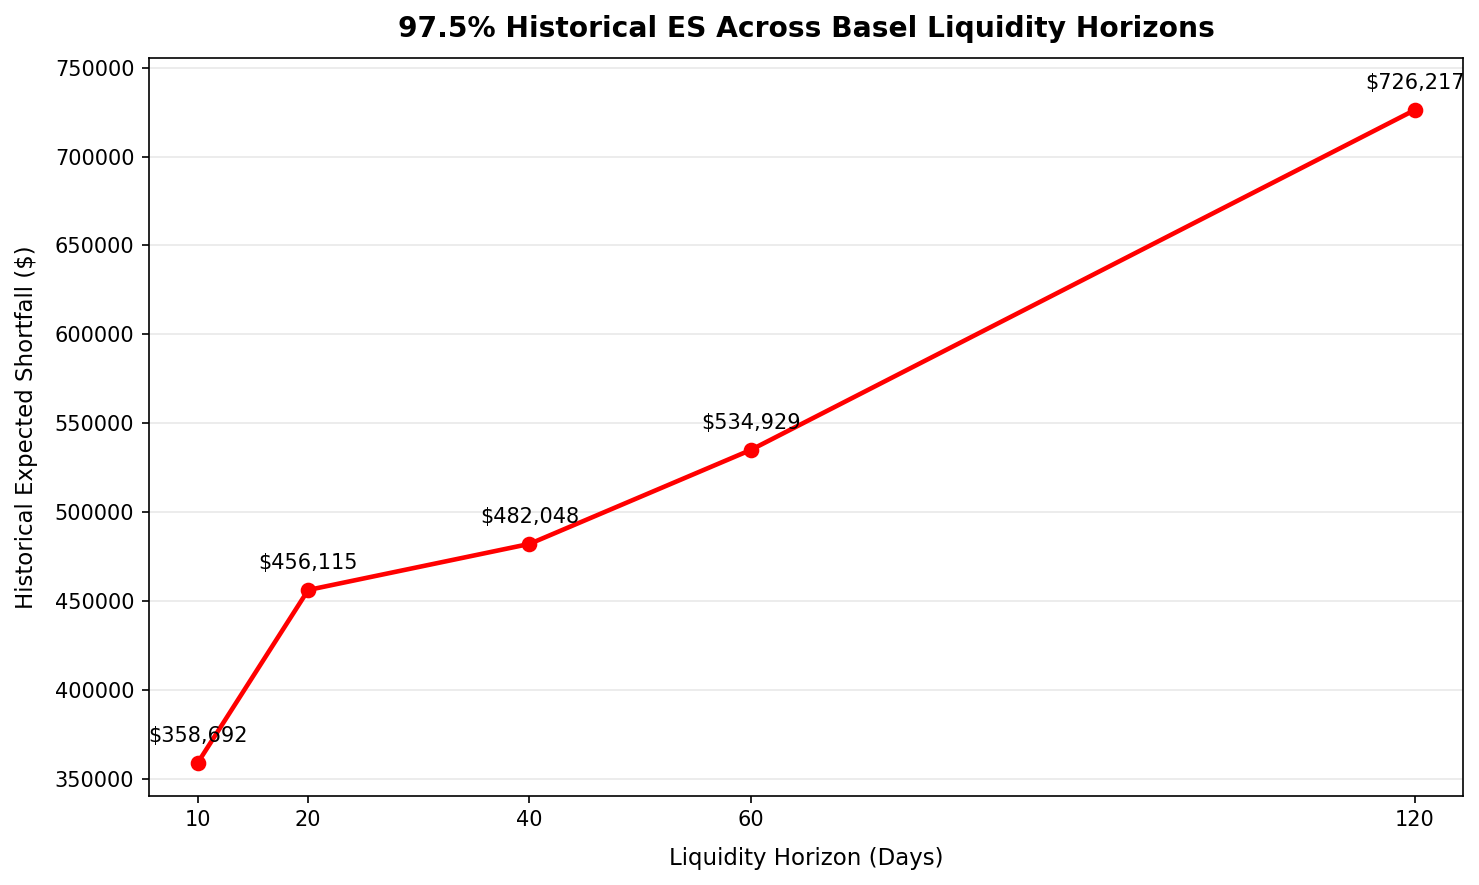

In [18]:
plot_data = liquidity_horizon_es.copy()

fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

x = plot_data["Liquidity Horizon (Days)"]
y = plot_data["Historical ES"]

# 1. Plot line with circular markers
ax.plot(
    x,
    y,
    marker="o",
    markersize=6.5,
    linewidth=2.2,
    color="red",
    zorder=3
)

# 2. Add text annotations positioned dynamically above points
for xi, yi in zip(x, y):
    ax.annotate(
        f"${yi:,.0f}",
        xy=(xi, yi),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        color="black",
        zorder=4
    )

# 3. Dynamic Y-axis limits (zoomed into the data range with headroom for top labels)
y_min = y.min()
y_max = y.max()
y_range = y_max - y_min

ax.set_ylim(y_min - 0.05 * y_range, y_max + 0.08 * y_range)

# Format Y-axis to plain integers
ax.ticklabel_format(style="plain", axis="y")

# 4. X-axis ticks & margins
ax.set_xticks(x)
x_margin = (x.max() - x.min()) * 0.04
ax.set_xlim(x.min() - x_margin, x.max() + x_margin)

# 5. Labels & Title
ax.set_title(
    "97.5% Historical ES Across Basel Liquidity Horizons",
    fontsize=13.5,
    fontweight="bold",
    pad=10
)
ax.set_xlabel("Liquidity Horizon (Days)", fontsize=11, labelpad=8)
ax.set_ylabel("Historical Expected Shortfall ($)", fontsize=11, labelpad=8)

# 6. Subtle horizontal gridlines
ax.grid(axis="y", linestyle="-", color="#e0e0e0", alpha=0.7, zorder=0)

plt.tight_layout()
plt.show()

## Basel-Style Liquidity-Horizon Aggregation

The Basel liquidity-horizon framework starts with a 10-day Expected Shortfall calculated using all relevant risk factors and then incorporates additional partial Expected Shortfall measures for risk factors associated with longer liquidity horizons.

For this simplified portfolio, the risk factors are mapped to illustrative Basel liquidity horizons based on their broad risk-factor categories. EURUSD, GBPUSD, USDJPY, and the S&P 500 are assigned 10-day horizons, while Gold is assigned a 20-day horizon.

The resulting aggregation is an educational approximation of the Basel liquidity-horizon methodology. It is not a complete regulatory implementation because the portfolio does not contain the full range of risk-factor structures, positions, desk mappings, or regulatory data required for an actual FRTB calculation.

In [19]:
# ============================================================
# Basel-Style Liquidity-Horizon Aggregation
# ============================================================

# ------------------------------------------------------------
# 1. Illustrative Basel liquidity-horizon mapping
# ------------------------------------------------------------

risk_factor_liquidity_horizons = {
    "EURUSD": 10,
    "GBPUSD": 10,
    "USDJPY": 10,
    "SP500": 10,
    "GOLD": 20
}

print("Illustrative Risk-Factor Liquidity-Horizon Mapping")

liquidity_mapping = pd.DataFrame({
    "Risk Factor": risk_factor_liquidity_horizons.keys(),
    "Liquidity Horizon (Days)": risk_factor_liquidity_horizons.values()
})

display(
    liquidity_mapping.style
    .hide(axis="index")
)

Illustrative Risk-Factor Liquidity-Horizon Mapping


Risk Factor,Liquidity Horizon (Days)
EURUSD,10
GBPUSD,10
USDJPY,10
SP500,10
GOLD,20


## Basel Liquidity-Horizon Scaling

The Basel liquidity-horizon framework uses a 10-day base horizon and incorporates additional liquidity-horizon increments using square-root scaling.

For each liquidity horizon, the scaling factor is based on the incremental horizon beyond the previous liquidity bucket:

**Scaling Factor = √[(LHⱼ − LHⱼ₋₁) / 10]**

where 10 days is the Basel base horizon.

For the specified liquidity horizons of 10, 20, 40, 60, and 120 days, the incremental scaling factors are:

- 20-day horizon: √[(20 − 10) / 10] = **1.000**
- 40-day horizon: √[(40 − 20) / 10] = **1.414**
- 60-day horizon: √[(60 − 40) / 10] = **1.414**
- 120-day horizon: √[(120 − 60) / 10] = **2.449**

The partial Expected Shortfall for each liquidity-horizon subset is calculated over the 10-day base interval without first scaling it from a shorter horizon. The resulting components are then combined using the Basel-style square-root aggregation.

> **Implementation note:** This project applies the liquidity-horizon mechanics to a simplified five-factor portfolio for educational purposes. It is not a complete regulatory FRTB implementation.

In [20]:
# ============================================================
# Basel-Style Liquidity-Adjusted Expected Shortfall
# ============================================================

# Basel liquidity horizons
basel_horizons = [10, 20, 40, 60, 120]

# ------------------------------------------------------------
# 1. Full portfolio 10-day ES
# ------------------------------------------------------------

full_portfolio_es = engine.calculate(
    confidence=0.975,
    horizon=10,
    methodology="historical"
)["Expected Shortfall"]


# ------------------------------------------------------------
# 2. Calculate partial ES for each liquidity horizon
# ------------------------------------------------------------

partial_es = {}

for horizon in basel_horizons[1:]:

    # Select risk factors whose liquidity horizon
    # is at least as long as the current Basel horizon
    selected_factors = [
        factor
        for factor, factor_horizon
        in risk_factor_liquidity_horizons.items()
        if factor_horizon >= horizon
    ]

    # If no risk factors remain, the partial ES is zero
    if not selected_factors:

        partial_es[horizon] = 0.0

    else:

        subset_sensitivities = sensitivities[
            selected_factors
        ]

        subset_prices = market_prices[
            selected_factors
        ]

        subset_engine = RiskEngine(
            sensitivities=subset_sensitivities,
            risk_factor_prices=subset_prices
        )

        partial_es[horizon] = subset_engine.calculate(
            confidence=0.975,
            horizon=10,
            methodology="historical"
        )["Expected Shortfall"]


# ------------------------------------------------------------
# 3. Basel liquidity-horizon scaling
# ------------------------------------------------------------

basel_components = []

previous_horizon = 10

for horizon in basel_horizons[1:]:

    incremental_horizon = horizon - previous_horizon

    scaling_factor = np.sqrt(
        incremental_horizon / 10
    )

    scaled_component = (
        partial_es[horizon]
        * scaling_factor
    )

    basel_components.append({
        "Liquidity Horizon": horizon,
        "Partial ES": partial_es[horizon],
        "Incremental Horizon": incremental_horizon,
        "Scaling Factor": scaling_factor,
        "Scaled ES Component": scaled_component
    })

    previous_horizon = horizon


basel_components_df = pd.DataFrame(
    basel_components
)


# ------------------------------------------------------------
# 4. Calculate final liquidity-adjusted ES
# ------------------------------------------------------------

liquidity_adjusted_es = np.sqrt(
    full_portfolio_es ** 2
    + np.sum(
        basel_components_df["Scaled ES Component"] ** 2
    )
)


# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("Basel-Style Liquidity-Adjusted Expected Shortfall")
print("Confidence Level: 97.5%")
print("Base Horizon: 10 days")
print()

print(
    f"Full Portfolio 10-Day ES: "
    f"${full_portfolio_es:,.2f}"
)

print(
    f"Liquidity-Adjusted ES: "
    f"${liquidity_adjusted_es:,.2f}"
)

print()

display(
    basel_components_df.style
    .hide(axis="index")
    .format({
        "Partial ES": "${:,.2f}",
        "Incremental Horizon": "{:.0f}",
        "Scaling Factor": "{:.3f}",
        "Scaled ES Component": "${:,.2f}"
    })
)

Basel-Style Liquidity-Adjusted Expected Shortfall
Confidence Level: 97.5%
Base Horizon: 10 days

Full Portfolio 10-Day ES: $358,691.77
Liquidity-Adjusted ES: $367,597.69



Liquidity Horizon,Partial ES,Incremental Horizon,Scaling Factor,Scaled ES Component
20,"$80,425.57",10,1.000,"$80,425.57"
40,$0.00,20,1.414,$0.00
60,$0.00,20,1.414,$0.00
120,$0.00,60,2.449,$0.00


## Basel-Style Liquidity-Adjusted ES — Interpretation

The 10-day 97.5% Historical Expected Shortfall for the full portfolio is used as the base measure for the liquidity-horizon adjustment.

The liquidity-adjusted Expected Shortfall is higher than the base 10-day Expected Shortfall after incorporating the additional liquidity-horizon component.

In this simplified framework, the increase is driven by the Gold risk factor, which is assigned a 20-day liquidity horizon. The remaining risk factors are assigned 10-day horizons and therefore do not generate additional liquidity-horizon components.

The result demonstrates the mechanics of liquidity-horizon adjustment within the simplified portfolio. It should not be interpreted as a regulatory FRTB capital measure because the project does not implement the complete Basel risk-factor, desk, stressed-ES, and capital-calculation framework.

## Basel-Oriented Stressed Expected Shortfall

The Basel market-risk framework requires Expected Shortfall to be calibrated to a period of significant financial stress.

The stressed calibration is intended to capture the effect of stressed market conditions and stressed relationships between relevant risk factors.

This project uses a separate historical stress-period analysis to demonstrate the concept of stressed Expected Shortfall. The implementation is educational and does not represent the complete Basel stressed-ES calculation or regulatory capital framework.

In [21]:
# ============================================================
# Educational Stress-Period Selection
# ============================================================

# June 2022 market-stress window
stress_start = "2022-05-01"
stress_end = "2022-07-31"

stress_prices = market_prices.loc[
    stress_start:stress_end
].copy()

stress_returns = (
    stress_prices
    .pct_change(fill_method=None)
    .dropna()
)

print("Educational Stress Period")
print(f"Start Date: {stress_returns.index.min().date()}")
print(f"End Date: {stress_returns.index.max().date()}")
print(f"Observations: {len(stress_returns)}")
print(f"Risk Factors: {list(stress_returns.columns)}")

Educational Stress Period
Start Date: 2022-05-03
End Date: 2022-07-29
Observations: 61
Risk Factors: ['EURUSD', 'GBPUSD', 'USDJPY', 'SP500', 'GOLD']


## Stress Window Rationale

The selected window covers **3 May 2022 to 29 July 2022** and captures a concentrated period of elevated market stress within the available historical sample.

The period was characterized by high inflation, aggressive monetary-policy tightening, increased interest-rate volatility, substantial equity-market declines and volatility, U.S. dollar strength, and continued geopolitical and commodity-market uncertainty.

A key monetary-policy event occurred in June 2022, when the Federal Reserve **raised the target range for the federal funds rate by 75 basis points, from 0.75%–1.00% to 1.50%–1.75%**. This represented a significant acceleration in monetary-policy tightening in response to elevated inflation.

These conditions are relevant to the portfolio because the selected risk factors include **EURUSD, GBPUSD, USDJPY, S&P 500, and Gold**.

The window is therefore used as an educational historical stress period to demonstrate stressed Expected Shortfall mechanics. It is not intended to represent the full Basel stressed-ES calibration methodology.

In [22]:
# ============================================================
# Educational Stressed Expected Shortfall
# ============================================================

stress_engine = RiskEngine(
    sensitivities=sensitivities,
    risk_factor_prices=stress_prices
)

stressed_es_result = stress_engine.calculate(
    confidence=0.975,
    horizon=10,
    methodology="historical"
)

stressed_es = stressed_es_result["Expected Shortfall"]
stressed_var = stressed_es_result["VaR"]

print("Educational Stressed Expected Shortfall")
print("Confidence Level: 97.5%")
print("Base Horizon: 10 days")
print(f"Stressed Historical VaR: ${stressed_var:,.2f}")
print(f"Stressed Historical ES:  ${stressed_es:,.2f}")

Educational Stressed Expected Shortfall
Confidence Level: 97.5%
Base Horizon: 10 days
Stressed Historical VaR: $359,907.69
Stressed Historical ES:  $369,808.48


## Educational Stressed ES — Interpretation

The selected historical stress window is used to demonstrate stressed Expected Shortfall using a 97.5% confidence level and a 10-day base horizon.

Expected Shortfall is higher than VaR because it measures the average loss beyond the VaR threshold within the stressed-period loss distribution.

This analysis demonstrates the concept of calibrating Expected Shortfall to a separate period of elevated market stress. It is an educational implementation and should not be interpreted as a complete Basel stressed-ES calculation or regulatory capital measure.

## Educational 1-Day VaR Backtesting

VaR backtesting compares the model's predicted one-day VaR with subsequent one-day portfolio losses to evaluate whether the risk model is reasonably capturing the frequency of tail-loss events.

The Basel market-risk framework uses one-day VaR at the 99% confidence level for bank-wide backtesting and evaluates exceptions over a historical observation period. An exception occurs when the observed loss exceeds the corresponding VaR measure.

This project implements an educational backtesting exercise using a 250-trading-day rolling window to estimate one-day 99% Historical VaR from the portfolio's historical P&L.

The backtest calculates the observed exception rate from the available historical observations. The number of exceptions and the resulting exception rate therefore depend on the market-data sample and the rolling backtesting window.

The exercise is intended to demonstrate the backtesting concept and is not a complete regulatory backtesting framework because actual and hypothetical trading P&L are not separately available.

In [23]:
# ============================================================
# Educational 1-Day 99% Historical VaR Backtesting
# ============================================================

# 1. Calculate daily portfolio P&L
portfolio_pnl = returns @ sensitivities

# Convert P&L into loss:
# positive values represent portfolio losses
portfolio_loss = -portfolio_pnl

# 2. Define backtesting parameters
backtest_confidence = 0.99
backtest_window = 250

backtest_results = []

# 3. Calculate rolling Historical VaR
#    using only observations available before the test day

for i in range(backtest_window, len(portfolio_loss)):

    historical_window = portfolio_loss.iloc[
        i - backtest_window:i
    ]

    var_99 = historical_window.quantile(
        backtest_confidence
    )

    realized_loss = portfolio_loss.iloc[i]

    backtest_results.append({
        "Date": portfolio_loss.index[i],
        "VaR 99%": var_99,
        "Realized Loss": realized_loss,
        "Exception": realized_loss > var_99
    })

# 4. Create backtesting DataFrame
backtest_df = pd.DataFrame(backtest_results)

backtest_df = backtest_df.set_index("Date")

# 5. Calculate exception statistics
total_observations = len(backtest_df)
total_exceptions = backtest_df["Exception"].sum()
exception_rate = total_exceptions / total_observations

print("Educational 1-Day 99% Historical VaR Backtest")
print(f"Backtesting observations: {total_observations}")
print(f"Rolling window: {backtest_window} trading days")
print(f"VaR exceptions: {total_exceptions}")
print(f"Exception rate: {exception_rate:.2%}")

# 6. Display VaR exception observations

exception_table = backtest_df[
    backtest_df["Exception"]
].copy()

display(
    exception_table.style
    .format({
        "VaR 99%": "${:,.2f}",
        "Realized Loss": "${:,.2f}"
    })
)

Educational 1-Day 99% Historical VaR Backtest
Backtesting observations: 1002
Rolling window: 250 trading days
VaR exceptions: 8
Exception rate: 0.80%


,VaR 99%,Realized Loss,Exception
Date,,,
2024-04-30 00:00:00,"$79,257.61","$87,033.15",True
2024-07-24 00:00:00,"$83,567.60","$96,558.34",True
2024-07-25 00:00:00,"$87,171.13","$89,769.02",True
2024-08-02 00:00:00,"$87,171.13","$101,461.06",True
2024-08-05 00:00:00,"$88,561.01","$96,185.96",True
2025-04-04 00:00:00,"$94,553.68","$119,895.94",True
2025-04-07 00:00:00,"$96,375.88","$114,438.37",True
2026-01-30 00:00:00,"$85,378.48","$123,800.75",True


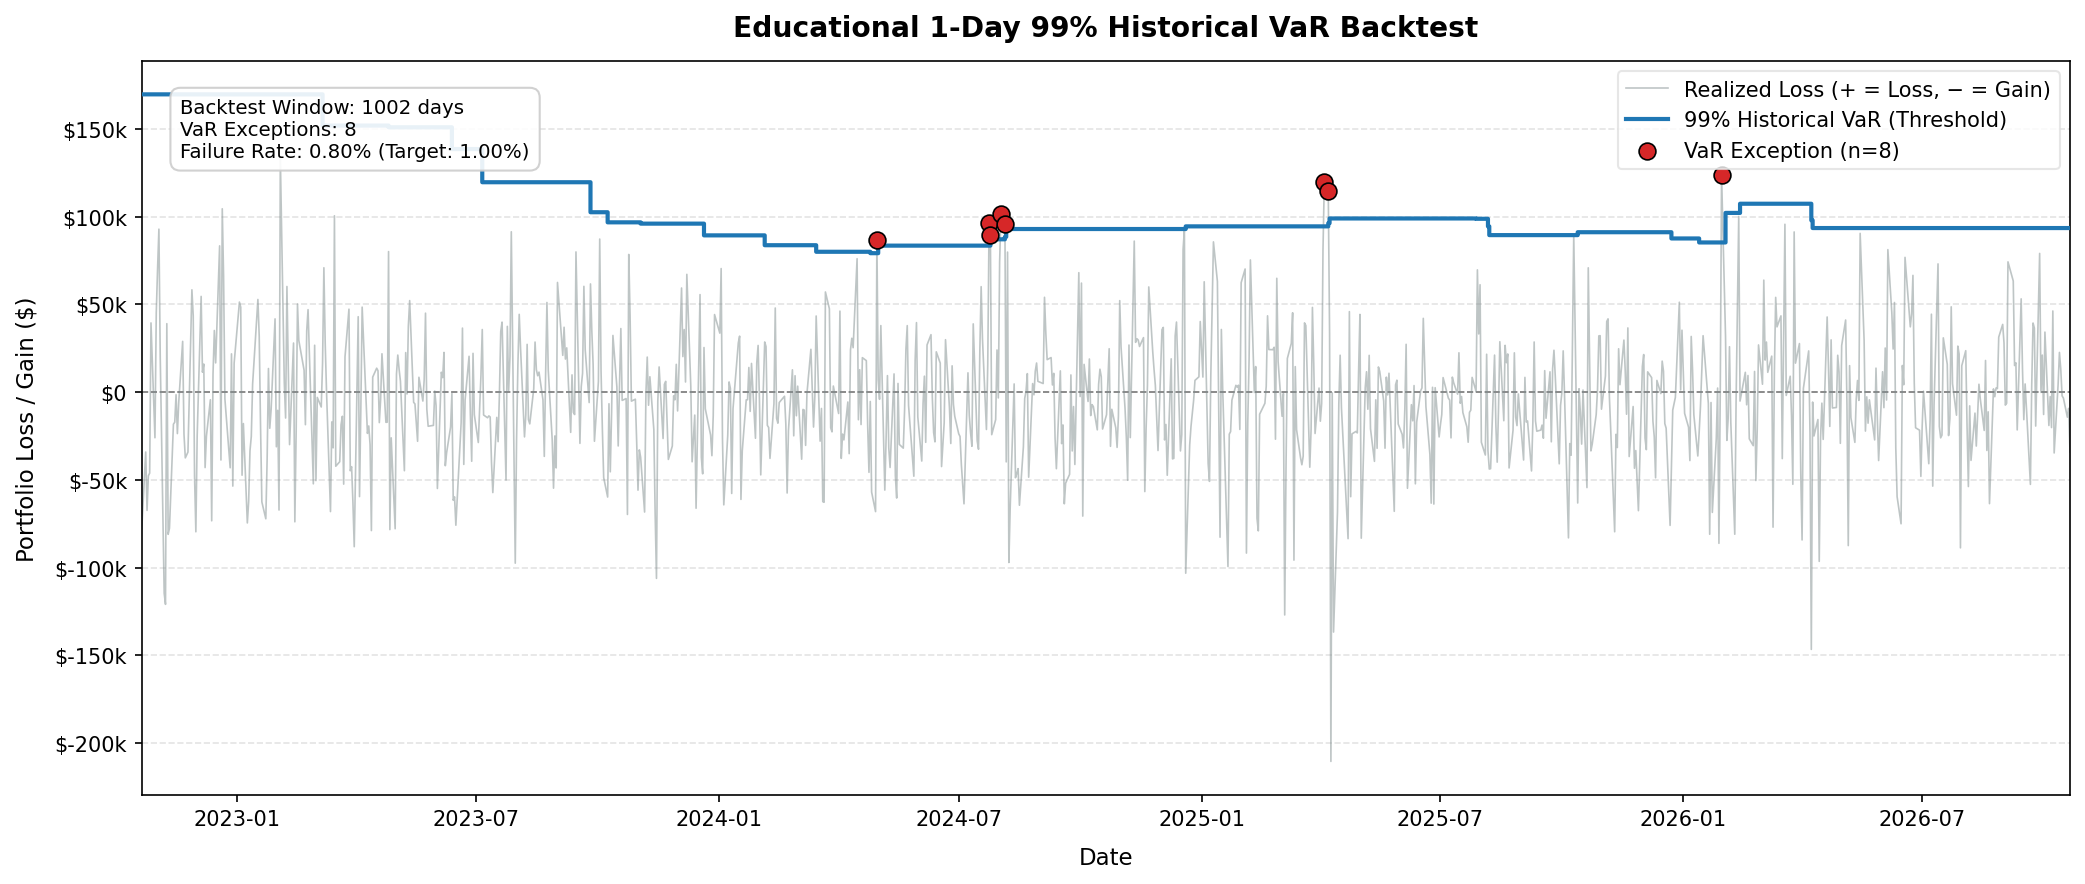

In [24]:
fig, ax = plt.subplots(figsize=(14, 6), dpi=150)

# ------------------------------------------------------------
# 1. Background Realized Loss (Subdued to reduce clutter)
# ------------------------------------------------------------
ax.plot(
    backtest_df.index,
    backtest_df["Realized Loss"],
    label="Realized Loss (+ = Loss, − = Gain)",
    color="#7f8c8d",          # Neutral slate gray
    linewidth=0.8,
    alpha=0.5,
    zorder=2
)

# ------------------------------------------------------------
# 2. Rolling 99% VaR Line (Prominent stepped threshold)
# ------------------------------------------------------------
ax.plot(
    backtest_df.index,
    backtest_df["VaR 99%"],
    label="99% Historical VaR (Threshold)",
    color="#1f77b4",          # Deep blue
    linewidth=2.0,
    drawstyle="steps-post",   # Reflects true rolling step adjustments
    zorder=3
)

# ------------------------------------------------------------
# 3. VaR Exceptions (Bold red highlight)
# ------------------------------------------------------------
exceptions = backtest_df[backtest_df["Exception"]]

ax.scatter(
    exceptions.index,
    exceptions["Realized Loss"],
    color="#d62728",          # High-contrast crimson red
    edgecolor="black",
    linewidth=0.8,
    s=65,
    marker="o",
    label=f"VaR Exception (n={len(exceptions)})",
    zorder=5
)

# ------------------------------------------------------------
# 4. Zero Baseline & Grid
# ------------------------------------------------------------
ax.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.6, zorder=1)
ax.grid(axis="y", linestyle="--", alpha=0.35, zorder=0)

# ------------------------------------------------------------
# 5. Format Y-Axis as Currency ($k / $M)
# ------------------------------------------------------------
def currency_fmt(x, pos):
    if abs(x) >= 1e6:
        return f"${x*1e-6:.1f}M"
    elif abs(x) >= 1e3:
        return f"${x*1e-3:.0f}k"
    return f"${x:.0f}"

ax.yaxis.set_major_formatter(FuncFormatter(currency_fmt))

# ------------------------------------------------------------
# 6. Summary Stats Callout Box
# ------------------------------------------------------------
total_obs = len(backtest_df)
num_exceptions = len(exceptions)
rate = (num_exceptions / total_obs) * 100 if total_obs > 0 else 0

stats_text = (
    f"Backtest Window: {total_obs} days\n"
    f"VaR Exceptions: {num_exceptions}\n"
    f"Failure Rate: {rate:.2f}% (Target: 1.00%)"
)

ax.text(
    0.02, 0.95,
    stats_text,
    transform=ax.transAxes,
    fontsize=9.5,
    verticalalignment="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="#cccccc", alpha=0.9)
)

# ------------------------------------------------------------
# 7. Labels, Limits & Legend
# ------------------------------------------------------------
ax.set_title("Educational 1-Day 99% Historical VaR Backtest", fontsize=13.5, fontweight="bold", pad=12)
ax.set_xlabel("Date", fontsize=11, labelpad=8)
ax.set_ylabel("Portfolio Loss / Gain ($)", fontsize=11, labelpad=8)

ax.set_xlim(backtest_df.index.min(), backtest_df.index.max())
ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#e0e0e0")

plt.tight_layout()
plt.show()

## VaR Backtesting — Interpretation

The backtest compares realized one-day portfolio losses with the corresponding rolling 99% Historical VaR threshold.

A VaR exception occurs when the realized portfolio loss exceeds the model's estimated 99% VaR for that day.

The observed exception rate can be compared with the nominal 1% tail probability associated with a 99% VaR model. A rate close to 1% is broadly consistent with the expected frequency of exceptions, although exception frequency alone is not sufficient to establish model adequacy.

The backtest is based on the simplified portfolio P&L and Historical VaR framework used in this project. It is therefore an educational validation exercise rather than a complete regulatory backtesting framework.

In particular, the analysis does not separately incorporate actual and hypothetical trading P&L or the full Basel backtesting and supervisory assessment framework.

## Overall Project Assessment

This project developed a simplified portfolio market-risk framework and progressively extended it toward selected Basel/FRTB concepts.

The core risk engine compares Historical, Parametric, and Monte Carlo approaches for VaR and Expected Shortfall and evaluates the impact of confidence levels and holding periods.

The project then extends the analysis with scenario-based stress testing, a 97.5% Basel-oriented Expected Shortfall framework, illustrative liquidity-horizon adjustments, an educational stressed-period analysis, and one-day 99% Historical VaR backtesting.

These extensions demonstrate selected market-risk and FRTB concepts while remaining within a simplified five-factor, linear-sensitivity framework.

The project is therefore best viewed as an educational market-risk modelling case study that demonstrates the progression from core risk measurement toward more advanced regulatory-oriented concepts. It is not a complete Basel/FRTB regulatory capital implementation.